# Fast distributed NMPC by exploiting the parametric structure of the local problems: real-time ADMM

Companion code for the paper

> D. Krishnamoorthy, *Fast Distributed Nonlinear Model Predictive Control by Exploiting the
> Parametric Structure of the Local Problems*, submitted to the European Control Conference (ECC), 2027.

The notebook runs the two simulation studies of the paper in a real-time setting, with three
quadrotors that must avoid collisions with each other:

1. **Point-to-point:** the quadrotors swap sides through a common region.
2. **Tracking:** the quadrotors follow three intersecting elliptical orbits.

**Real-time setting.** In this notebook, the ADMM iterations are limited by the sampling time
$T_s=100$ ms rather than by a maximum number of rounds. In every sample, the communication rounds
continue until ADMM has converged or until the next round would no longer be completed within
$T_s$. In the latter case, the iterations are stopped, and each agent applies the first input of
its latest completed local iterate, whether ADMM has converged or not.

Three controllers are compared in each study:

- **centralized NMPC**, solved to convergence in every sample (benchmark without deadline);
- **standard distributed NMPC**: consensus ADMM, where every agent solves its local NLP exactly
  (IPOPT) in every communication round;
- **proposed (sensitivity-assisted) distributed NMPC**: the same ADMM scheme, where the local
  exact solves are replaced by a single Newton step on the active-set KKT conditions whenever
  the ADMM residuals are small and the active set does not change.

## 0. Setup

In [13]:
import copy
import io
import pickle
import shutil
import time
from pathlib import Path

import casadi as ca
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from scipy.sparse.csgraph import reverse_cuthill_mckee


FIG_DIR, RES_DIR = Path('figures'), Path('results')
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)

# Plot style. LaTeX is used for all text if a working installation is found; otherwise
# Computer Modern is used with Matplotlib's built-in math renderer.
TEX_RC = {'text.usetex': True, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman'],
          'text.latex.preamble': r'\usepackage{amsmath}'}


def tex_available():
    if shutil.which('latex') is None:
        return False
    try:
        with plt.rc_context(TEX_RC):
            fig = plt.figure(); fig.text(0, 0, r'$\frac{1}{M}\|x\|$ [m]'); fig.savefig(io.BytesIO(), format='pdf')
        return True
    except Exception:
        return False
    finally:
        plt.close('all')


USE_TEX = tex_available()
print(f'CasADi {ca.__version__} | LaTeX text in figures: {USE_TEX}')
if USE_TEX:
    plt.rcParams.update(TEX_RC)
else:
    plt.rcParams.update({'text.usetex': False, 'font.family': 'serif', 'font.serif': ['cmr10'],
                         'mathtext.fontset': 'cm', 'axes.formatter.use_mathtext': True})
plt.rcParams.update({'font.size': 8, 'axes.labelsize': 8, 'legend.fontsize': 7,
                     'xtick.labelsize': 7, 'ytick.labelsize': 7, 'figure.dpi': 110})

AGENT_COLORS = ['#2a78d6', '#eb6834', '#1baf7a']
METHOD_STYLE = {'central': dict(color='#000000', ls=':', label='Centralized NMPC'),
                'nlp':     dict(color='#ff0000cd', ls='--', label='Standard distributed NMPC'),
                'sens':    dict(color='#6250d6', ls='-', label='Proposed')}
METHODS = ['central', 'nlp', 'sens']

CasADi 3.7.2 | LaTeX text in figures: True


## 1. Quadrotor model and problem data

State $x\in\mathbb R^{12}$: angles $(\theta,\phi,\psi)$ (indices 0–2), position $\xi=(x,y,z)$
(3–5), angular rates (6–8) and linear velocities (9–11). Input $u\in\mathbb R^4$: total thrust
and three angular accelerations. The model follows Bemporad et al. (2009).

The controllers predict with a fixed-step RK4 discretization (multiple shooting). The plant is
simulated with CVODES.

In [14]:
# model parameters
m, beta, g0 = 1.846, 0.2, 9.81
nx, nu = 12, 4
u_hover = np.array([m * g0, 0, 0, 0])
Fmax, tau_max = 2.0 * m * g0, 10.0          # input bounds
Rw = np.array([0.1, 1.0, 1.0, 1.0])         # input weights

# MPC and ADMM parameters
Ts, N, M = 0.1, 20, 3                       # sampling time [s], horizon, number of agents
dmin = 1.0                                  # minimum inter-agent distance [m]
rho = 1000.0                                # ADMM penalty
EPS = 1e-2                                  # ADMM tolerance on the primal and dual residuals
T_BUDGET = 0.5*Ts                               # computation budget for the ADMM rounds of one sample [s]


def quad_ode():
    x = ca.SX.sym('x', nx); u = ca.SX.sym('u', nu)
    F = u[0]
    dx = ca.vertcat(x[6], x[7], x[8],                     # angle rates
                    x[9], x[10], x[11],                   # velocities
                    u[1], u[2], u[3],                     # angular accelerations
                    (-F * ca.sin(x[0]) - beta * x[9]) / m,
                    (F * ca.cos(x[0]) * ca.sin(x[1]) - beta * x[10]) / m,
                    -g0 + (F * ca.cos(x[0]) * ca.cos(x[1]) - beta * x[11]) / m)
    return ca.Function('f', [x, u], [dx], ['x', 'u'], ['xdot'])


def rk4(f, h):
    x = ca.SX.sym('x', nx); u = ca.SX.sym('u', nu)
    k1 = f(x, u); k2 = f(x + h / 2 * k1, u); k3 = f(x + h / 2 * k2, u); k4 = f(x + h * k3, u)
    return ca.Function('Fd', [x, u], [x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)])


f_ct = quad_ode()
F_d = rk4(f_ct, Ts)                                       # prediction model
_x, _u = ca.SX.sym('x', nx), ca.SX.sym('u', nu)
plant = ca.integrator('plant', 'cvodes', {'x': _x, 'p': _u, 'ode': f_ct(_x, _u)}, 0, Ts)


def x_init(pos):
    """Hover state at position pos."""
    x = np.zeros(nx); x[3:6] = pos; return x

## 2. Local ADMM subproblems as parametric NLPs

Each agent $i$ holds its own state and input trajectories and local copies $y_i^j$ of the
other agents' predicted positions. Its consensus vector $c_i$ collects its own positions and these
copies. Collision avoidance is enforced against the copies. Given the parameter
$\theta_i=(\hat x_i,\, r_i,\, z,\, \lambda_i)$, where $r_i$ is the target (point-to-point) or the
reference trajectory over the horizon (tracking), agent $i$ solves

$$
\min_{w_i}\; J_i(w_i; r_i) + \lambda_i^\top(c_i(w_i)-z) + \tfrac{\rho}{2}\|c_i(w_i)-z\|^2
\quad\text{s.t.}\quad x_{i,0}=\hat x_i,\; x_{i,k+1}=F(x_{i,k},u_{i,k}),\; u_{i,k}\in\mathcal U,\;
\|\xi_{i,k}-y^j_{i,k}\|^2\ge d_{\min}^2 .
$$

The coordinator then updates $z$ (averaging) and $\lambda_i$ (dual ascent).

The same `Opti` model provides (i) the exact local solve with IPOPT, warm-started in the primal
and dual variables, and (ii) the symbolic KKT ingredients for the sensitivity update.

In [15]:
nX, nU, nY = nx * (N + 1), nu * N, 3 * N * (M - 1)
nC = 3 * N * M                   # consensus vector of one agent: positions of all agents, k = 1..N
nW = nX + nU + nY                # local decision vector


def unpack_w(W, i):
    """W -> X (nx x N+1), U (nu x N), list C[j] (3 x N): own positions for j = i, local copies otherwise."""
    X = ca.reshape(W[:nX], nx, N + 1)
    U = ca.reshape(W[nX:nX + nU], nu, N)
    Yall = W[nX + nU:]
    C, cnt = [], 0
    for j in range(M):
        if j == i:
            C.append(X[3:6, 1:])
        else:
            C.append(ca.reshape(Yall[cnt * 3 * N:(cnt + 1) * 3 * N], 3, N)); cnt += 1
    return X, U, C


def make_p(x0, ref, Z, Lam_i):
    """Parameter vector theta_i = (x0, ref, z, lambda_i)."""
    return np.concatenate([x0, np.ravel(ref, order='F'), Z.ravel(order='F'), Lam_i.ravel(order='F')])


IPOPT_OPTS = {'print_level': 0, 'sb': 'yes', 'tol': 1e-8}
CASADI_OPTS = {'expand': True, 'print_time': False, 'error_on_fail': False, 'record_time': True}


class Agent:
    """Local ADMM subproblem of agent i, with exact solve and sensitivity update.

    n_ref : length of the reference part r_i of the parameter
    cost  : cost(X, U, ref) -> tracking cost J_i
    """

    def __init__(self, i, n_ref, cost):
        self.i, self.nP = i, nx + n_ref + 2 * nC
        opti = ca.Opti()
        W = opti.variable(nW)
        P = opti.parameter(self.nP)
        x0, ref = P[:nx], P[nx:nx + n_ref]
        Z = ca.reshape(P[nx + n_ref:nx + n_ref + nC], 3, N * M)
        Lam = ca.reshape(P[nx + n_ref + nC:], 3, N * M)
        X, U, C = unpack_w(W, i)
        Cmat = ca.horzcat(*C)                                      # same layout as Z

        opti.minimize(cost(X, U, ref) + ca.dot(Lam, Cmat - Z) + rho / 2 * ca.sumsqr(Cmat - Z))
        opti.subject_to(X[:, 0] == x0)                             # initial-value embedding
        for k in range(N):
            opti.subject_to(X[:, k + 1] == F_d(X[:, k], U[:, k]))  # multiple shooting
            opti.subject_to(opti.bounded(0, U[0, k], Fmax))
            opti.subject_to(opti.bounded(-tau_max, U[1:, k], tau_max))
        for j in range(M):                                         # collision avoidance vs. local copies
            if j != i:
                for k in range(N):
                    opti.subject_to(ca.sumsqr(X[3:6, k + 1] - C[j][:, k]) >= dmin ** 2)

        opti.solver('ipopt', CASADI_OPTS,
                    {**IPOPT_OPTS, 'max_iter': 500, 'warm_start_init_point': 'yes',
                     'warm_start_bound_push': 1e-6, 'warm_start_mult_bound_push': 1e-6, 'mu_init': 1e-3})
        self.opti, self.W, self.P, self.ng = opti, W, P, opti.ng

        # KKT ingredients (CasADi convention: L = f + lam_g' g). Opti moves parametric terms such as
        # X[:, 0] = x0 into the bounds, so lbg/ubg are functions of the parameter.
        Lag = opti.f + ca.dot(opti.lam_g, opti.g)
        H, gradL = ca.hessian(Lag, W)
        self.kkt_fun = ca.Function('kkt', [W, opti.lam_g, P],
                                   [H, ca.jacobian(opti.g, W), gradL, opti.g]).expand()
        self.bnd_fun = ca.Function('bnd', [P], [opti.lbg, opti.ubg])
        lb, ub = self.bounds(np.zeros(self.nP))
        self.is_eq = lb == ub
        self.C_fun = ca.Function('C', [W], [Cmat])
        self.U0_fun = ca.Function('U0', [W], [U[:, 0]])
        self.XU_fun = ca.Function('XU', [W], [X, U])
        self._build_sens()

    def bounds(self, p):
        lb, ub = self.bnd_fun(p)
        return np.array(lb).ravel(), np.array(ub).ravel()

    def solve_nlp(self, p, w0, lam0):
        """Exact local solve with IPOPT (primal-dual warm start). Returns w, lam_g, IPOPT wall time."""
        self.opti.set_value(self.P, p)
        self.opti.set_initial(self.W, w0)
        self.opti.set_initial(self.opti.lam_g, lam0)
        sol = self.opti.solve_limited()
        return (np.array(sol.value(self.W)).ravel(), np.array(sol.value(self.opti.lam_g)).ravel(),
                self.opti.stats()['t_wall_total'])

    def active_set(self, w, lam, p, tol=1e-5):
        """Strongly active inequality constraints (lower / upper bound) at a KKT point."""
        g = np.array(self.kkt_fun(w, lam, p)[3]).ravel()
        lbg, ubg = self.bounds(p)
        lo = (~self.is_eq) & (g - lbg < tol) & (lam < -1e-8)
        up = (~self.is_eq) & (ubg - g < tol) & (lam > 1e-8)
        return lo, up

    # ---------- sensitivity update ----------
    def _build_sens(self):
        """CasADi function for one Newton step on the active-set KKT conditions.

        The KKT matrix has a fixed sparsity pattern: a 0/1 vector D marks the active constraints,
        and the multipliers of inactive constraints are set to zero. The matrix is reordered once
        with reverse Cuthill-McKee and the linear system is solved with a sparse QR factorization.
        """
        w = ca.SX.sym('w', nW); lam = ca.SX.sym('lam', self.ng); p = ca.SX.sym('p', self.nP)
        D = ca.SX.sym('D', self.ng); tgt = ca.SX.sym('tgt', self.ng)
        H, Jg, gradL, g = self.kkt_fun(w, D * lam, p)
        K = ca.blockcat([[H, Jg.T @ ca.diag(D)], [ca.diag(D) @ Jg, ca.diag(1 - D)]])
        r = ca.vertcat(gradL, D * (g - tgt) + (1 - D) * lam)
        colind, row = K.sparsity().get_ccs(); n = K.shape[0]
        S = sp.csc_matrix((np.ones(len(row)), row, colind), shape=(n, n))
        perm = list(reverse_cuthill_mckee((S + S.T).tocsr(), symmetric_mode=True))
        inv = list(np.argsort(perm))
        Kf = ca.Function('Kf', [w, lam, p, D, tgt], [K[perm, perm], r[perm]])
        wm, lm, pm, Dm, tm = [ca.MX.sym(nm, v.shape[0])
                              for nm, v in zip(['w', 'l', 'p', 'D', 't'], [w, lam, p, D, tgt])]
        Km, rm = Kf(wm, lm, pm, Dm, tm)
        d = ca.solve(Km, -rm, 'qr')[inv]
        w_new, l_new = wm + d[:nW], Dm * (lm + d[nW:])
        self.sens_fun = ca.Function('sens', [wm, lm, pm, Dm, tm],
                                    [w_new, l_new, self.kkt_fun(w_new, l_new, pm)[3]])

    def sens_step(self, w, lam, p, lo, up, viol_tol=1e-4):
        """Sensitivity update at the new parameter p with fixed active set (lo, up).

        Returns w+, lam+, wall time, and whether the step passes the acceptance test (no inactive
        constraint violated, no active multiplier with the wrong sign)."""
        t0 = time.perf_counter()
        act = self.is_eq | lo | up
        lbg, ubg = self.bounds(p)
        tgt = np.where(act, np.where(up, ubg, lbg), 0.0)
        w_, l_, g = self.sens_fun(w, lam, p, act.astype(float), tgt)
        w, lam, g = np.array(w_).ravel(), np.array(l_).ravel(), np.array(g).ravel()
        dt = time.perf_counter() - t0
        viol = (~act) & ((g < lbg - viol_tol) | (g > ubg + viol_tol))
        wrong = (lo & (lam > 1e-8)) | (up & (lam < -1e-8))
        return w, lam, dt, not (viol.any() or wrong.any())

## 3. Centralized NMPC

The same optimal control problem, solved jointly for all agents with all pairwise collision
constraints.

In [16]:
class Central:
    def __init__(self, n_ref, cost):
        opti = ca.Opti()
        self.X = [opti.variable(nx, N + 1) for _ in range(M)]
        self.U = [opti.variable(nu, N) for _ in range(M)]
        self.x0 = opti.parameter(nx, M)
        self.ref = [opti.parameter(n_ref) for _ in range(M)]
        J = 0
        for i in range(M):
            X, U = self.X[i], self.U[i]
            J += cost(X, U, self.ref[i])
            opti.subject_to(X[:, 0] == self.x0[:, i])
            for k in range(N):
                opti.subject_to(X[:, k + 1] == F_d(X[:, k], U[:, k]))
                opti.subject_to(opti.bounded(0, U[0, k], Fmax))
                opti.subject_to(opti.bounded(-tau_max, U[1:, k], tau_max))
        for i in range(M):
            for j in range(i + 1, M):
                for k in range(1, N + 1):
                    opti.subject_to(ca.sumsqr(self.X[i][3:6, k] - self.X[j][3:6, k]) >= dmin ** 2)
        opti.minimize(J)
        opti.solver('ipopt', CASADI_OPTS, {**IPOPT_OPTS, 'max_iter': 1000})
        self.opti = opti

    def solve(self, x0s, refs, X0, U0):
        self.opti.set_value(self.x0, np.array(x0s).T)
        for i in range(M):
            self.opti.set_value(self.ref[i], np.ravel(refs[i], order='F'))
            self.opti.set_initial(self.X[i], X0[i]); self.opti.set_initial(self.U[i], U0[i])
        sol = self.opti.solve_limited()
        return ([np.array(sol.value(v)) for v in self.X], [np.array(sol.value(v)) for v in self.U],
                self.opti.stats()['t_wall_total'])

## 4. Consensus ADMM for one sampling instant

`method='nlp'` is the standard scheme: every agent solves its local NLP exactly in every round.

`method='sens'` is the proposed scheme. An agent performs the sensitivity update instead of an
exact solve, except

1. in the first round of every sample (the measured state has changed);
2. while $\max(r,\delta)\ge R_{\rm sw}$, where $r$ and $\delta$ are the primal and dual residuals;
3. when the acceptance test detects an active-set change (fallback to an exact solve).

The active set is taken from the agent's most recent exact solve.

The agents are solved sequentially, and the duration of each round is the maximum computation
time over the agents, which emulates parallel execution. For exact solves, this is IPOPT's
`t_wall_total`; for sensitivity updates, it is the full wall time of the step.

**Deadline.** The rounds of one sample may use at most `t_budget` $=T_s$ of computation. A round
whose results would arrive after the deadline is discarded, and the latest completed iterate is
kept. If not even the first round fits, the agents apply the shifted solution of the previous
sample. Coordination and communication times are neglected, as in the computation times.

In [17]:
def initial_guess(agents, x0s, X0):
    """ADMM warm start from state-trajectory guesses X0[i] (nx x N+1); hover inputs, zero duals."""
    Z = np.hstack([X0[j][3:6, 1:] for j in range(M)])
    ws, U0 = [], []
    for i in range(M):
        U = np.tile(u_hover[:, None], (1, N))
        Y = [Z[:, j * N:(j + 1) * N].ravel('F') for j in range(M) if j != i]
        ws.append(np.concatenate([X0[i].ravel('F'), U.ravel('F')] + Y)); U0.append(U)
    S = dict(ws=ws, lams=[np.zeros(a.ng) for a in agents], Z=Z, Lams=[np.zeros((3, N * M)) for _ in range(M)])
    return S, U0


def consensus_update(agents, ws, Lams, Z):
    """Coordinator: z-update (averaging) and dual updates. Returns z, primal and dual residual."""
    C = [np.array(a.C_fun(ws[a.i])) for a in agents]
    Z_new = sum(C[i] + Lams[i] / rho for i in range(M)) / M
    for i in range(M):
        Lams[i] = Lams[i] + rho * (C[i] - Z_new)
    r = np.sqrt(sum(np.sum((C[i] - Z_new) ** 2) for i in range(M)))
    dz = np.sqrt(M) * np.linalg.norm(Z_new - Z)
    return Z_new, r, dz


def admm_sample(agents, x0s, refs, S, method, R_switch, t_budget=T_BUDGET, max_iter=10_000, eps=EPS):
    """One sampling instant of consensus-ADMM DMPC. S = dict(ws, lams, Z, Lams) is updated in place.

    The rounds stop when ADMM has converged or when the next round would end after t_budget
    (t_budget=None: no deadline). A round that misses the deadline is discarded."""
    ws, lams, Lams = S['ws'], S['lams'], S['Lams']
    h = dict(r=[], dz=[], t_round=[], n_nlp=0, n_sens=0, n_fallback=0, converged=False, timeout=False)
    active, use_sens, t_used = [None] * M, False, 0.0
    for _ in range(max_iter):
        ws_prev, lams_prev = list(ws), list(lams)  # latest completed iterate (arrays are replaced, not mutated)
        t_agents, cnt = [], dict(n_nlp=0, n_sens=0, n_fallback=0)
        for a in agents:
            i = a.i
            p = make_p(x0s[i], refs[i], S['Z'], Lams[i])
            done, dt = False, 0.0
            if method == 'sens' and use_sens and active[i] is not None:
                w, lam, dt, ok = a.sens_step(ws[i], lams[i], p, *active[i])
                if ok:
                    ws[i], lams[i] = w, lam; cnt['n_sens'] += 1; done = True
                else:
                    cnt['n_fallback'] += 1        # active-set change -> exact solve (time of the step is kept)
            if not done:
                ws[i], lams[i], dt_nlp = a.solve_nlp(p, ws[i], lams[i])
                dt += dt_nlp
                active[i] = a.active_set(ws[i], lams[i], p); cnt['n_nlp'] += 1
            t_agents.append(dt)
        t_round = max(t_agents)
        if t_budget is not None and t_used + t_round > t_budget:
            ws[:], lams[:] = ws_prev, lams_prev     # round not completed in time: discard it
            h['timeout'] = True
            break
        t_used += t_round
        for key in cnt:
            h[key] += cnt[key]
        S['Z'], r, dz = consensus_update(agents, ws, Lams, S['Z'])
        h['r'].append(r); h['dz'].append(dz); h['t_round'].append(t_round)
        use_sens = max(r, dz) < R_switch
        if r < eps and dz < eps:
            h['converged'] = True
            break
    return h


def shift(agents, S):
    """Shift all trajectories by one sample for warm starting (local multipliers are kept)."""
    def sh(A):
        B = A.copy()
        for j in range(M):
            b = A[:, j * N:(j + 1) * N]; B[:, j * N:(j + 1) * N] = np.hstack([b[:, 1:], b[:, -1:]])
        return B
    ws = []
    for a in agents:
        X, U = [np.array(v) for v in a.XU_fun(S['ws'][a.i])]
        X = np.hstack([X[:, 1:], X[:, -1:]]); U = np.hstack([U[:, 1:], U[:, -1:]])
        Cs = sh(np.array(a.C_fun(S['ws'][a.i])))
        Y = [Cs[:, j * N:(j + 1) * N].ravel('F') for j in range(M) if j != a.i]
        ws.append(np.concatenate([X.ravel('F'), U.ravel('F')] + Y))
    return dict(ws=ws, lams=[l.copy() for l in S['lams']], Z=sh(S['Z']), Lams=[sh(L) for L in S['Lams']])

## 5. Closed-loop simulation

In [18]:
def run_dmpc(agents, S_init, x_start, ref_seq, n_steps, method, R_switch):
    """Closed loop with distributed NMPC. ref_seq(k) returns the list of references at sample k."""
    S = copy.deepcopy(S_init); x = [xi.copy() for xi in x_start]
    log = dict(x=[np.array(x)], u=[], hist=[])
    for k in range(n_steps):
        h = admm_sample(agents, x, ref_seq(k), S, method, R_switch)
        u = [np.array(a.U0_fun(S['ws'][a.i])).ravel() for a in agents]
        x = [np.array(plant(x0=x[i], p=u[i])['xf']).ravel() for i in range(M)]
        log['x'].append(np.array(x)); log['u'].append(np.array(u)); log['hist'].append(h)
        S = shift(agents, S)
    log['x'], log['u'] = np.array(log['x']), np.array(log['u'])
    # computation time per sample: the full budget if the deadline was reached
    log['t'] = np.array([T_BUDGET if h['timeout'] else sum(h['t_round']) for h in log['hist']])
    return log


def run_central(central, x_start, ref_seq, n_steps, X0, U0):
    """Closed loop with centralized NMPC (shifted warm start)."""
    x = [xi.copy() for xi in x_start]; log = dict(x=[np.array(x)], u=[], t=[])
    for k in range(n_steps):
        X, U, t = central.solve(x, ref_seq(k), X0, U0)
        u = [U[i][:, 0] for i in range(M)]
        x = [np.array(plant(x0=x[i], p=u[i])['xf']).ravel() for i in range(M)]
        log['x'].append(np.array(x)); log['u'].append(np.array(u)); log['t'].append(t)
        X0 = [np.hstack([Xi[:, 1:], Xi[:, -1:]]) for Xi in X]; U0 = [np.hstack([Ui[:, 1:], Ui[:, -1:]]) for Ui in U]
    log['x'], log['u'], log['t'] = np.array(log['x']), np.array(log['u']), np.array(log['t'])
    return log


def run_all(agents, central, x_start, X0, ref_seq, n_steps, R_switch):
    """Offline ADMM initialization at t = 0 (exact solves to convergence, no deadline), then the
    three closed loops. The centralized NMPC is solved to convergence in every sample (benchmark)."""
    S_init, U0 = initial_guess(agents, x_start, X0)
    h0 = admm_sample(agents, x_start, ref_seq(0), S_init, 'nlp', R_switch, t_budget=None, max_iter=3000)
    print(f'offline ADMM initialization: {len(h0["r"])} rounds')
    logs = {}
    for name in METHODS:
        t0 = time.perf_counter()
        if name == 'central':
            logs[name] = run_central(central, x_start, ref_seq, n_steps, X0, U0)
        else:
            logs[name] = run_dmpc(agents, S_init, x_start, ref_seq, n_steps, name, R_switch)
        print(f'{METHOD_STYLE[name]["label"]:28s} simulated in {time.perf_counter() - t0:6.1f} s')
    return logs

## 6. Results: figures and summary

The result figure has the same panels as in the companion notebook without deadline. A second,
smaller figure shows how far ADMM gets within the deadline: the primal residual at the end of
each sample and the number of completed communication rounds.

In [19]:
PAIRS = [(i, j) for i in range(M) for j in range(i + 1, M)]
LW = {'central': 1.0, 'nlp': 1.5, 'sens': 0.75}     # standard drawn thick first, proposed on top


def style(name):
    st = dict(METHOD_STYLE[name]); st['lw'] = LW[name]; return st


def panel_label(a, s, x=0.03, y=0.95):
    a.text(x, y, s, transform=a.transAxes, ha='left', va='top',
           bbox=dict(facecolor='white', edgecolor='none', pad=1.0, alpha=0.85))


def min_pair_distance(P):
    """P: (T, M, 3) positions -> (T,) distance of the closest pair."""
    return np.min([np.linalg.norm(P[:, i] - P[:, j], axis=1) for i, j in PAIRS], axis=0)


def per_sample(log, key):
    return np.array([h[key] for h in log['hist']])


def results_figure(logs, ref_P, fname, panel_a, ref_orbit=None):
    """Panels: (a) paths [3D or x-y], (b) closest-pair distance, (c) average tracking error,
    (d) computation time per sample, (e) local update type of the proposed method.

    ref_P     : (T+1, M, 3) reference positions on the simulation grid (targets in scenario 1)
    panel_a   : '3d' (paths in 3D with targets) or 'xy' (paths in the x-y plane with ref_orbit)
    ref_orbit : (n, M, 3) reference orbits drawn in panel (a) for panel_a='xy'
    """
    n_steps = len(logs['nlp']['hist'])
    t_x, t_u = np.arange(n_steps + 1) * Ts, np.arange(n_steps) * Ts
    fig = plt.figure(figsize=(12, 3.4))
    gs = GridSpec(2, 3, figure=fig, width_ratios=[1.25, 1, 1], hspace=0.12, wspace=0.22)

    # (a) paths
    if panel_a == '3d':
        ax = fig.add_subplot(gs[:, 0], projection='3d')
        for name in METHODS:
            for i in range(M):
                ax.plot(*logs[name]['x'][:, i, 3:6].T, color=AGENT_COLORS[i],
                        ls=METHOD_STYLE[name]['ls'], lw=LW[name])
        for i in range(M):
            ax.scatter(*logs['nlp']['x'][0, i, 3:6], color=AGENT_COLORS[i], s=18, marker='o', depthshade=False)
            ax.scatter(*ref_P[0, i], color=AGENT_COLORS[i], s=45, marker='*', depthshade=False)
        ax.set_xlabel('$x$ [m]', labelpad=-4); ax.set_ylabel('$y$ [m]', labelpad=-4)
        ax.set_zlabel('$z$ [m]', labelpad=-6); ax.tick_params(pad=-2)
        for a in (ax.xaxis, ax.yaxis, ax.zaxis):
            a.pane.set_facecolor('white'); a.pane.set_edgecolor('#d0d0d0')
        h_extra = [Line2D([], [], color='k', marker='o', ls='', ms=3, label='start'),
                   Line2D([], [], color='k', marker='*', ls='', ms=6, label='target')]
        ax.text2D(0.0, 1.0, '(a)', transform=ax.transAxes, ha='left', va='top')
        legend_kw = dict(loc='upper left', bbox_to_anchor=(0.0, 0.92))
    else:
        ax = fig.add_subplot(gs[:, 0])
        for i in range(M):
            ax.plot(ref_orbit[:, i, 0], ref_orbit[:, i, 1], color=AGENT_COLORS[i], lw=3.0, alpha=0.2,
                    solid_capstyle='round')
        for name in METHODS:
            for i in range(M):
                P = logs[name]['x'][:, i, 3:6]
                ax.plot(P[:, 0], P[:, 1], color=AGENT_COLORS[i], ls=METHOD_STYLE[name]['ls'], lw=LW[name])
        for i in range(M):
            ax.plot(*logs['nlp']['x'][0, i, 3:5], 'o', color=AGENT_COLORS[i], ms=3.5)
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlabel('$x$ [m]'); ax.set_ylabel('$y$ [m]')
        h_extra = [Line2D([], [], color='k', lw=3.0, alpha=0.2, label='reference'),
                   Line2D([], [], color='k', marker='o', ls='', ms=3, label='start')]
        legend_kw = dict(loc='best', borderaxespad=0.2)
    h_agents = [Line2D([], [], color=AGENT_COLORS[i], lw=1.2, label=f'quad {i + 1}') for i in range(M)]
    ax.legend(handles=h_agents + h_extra, frameon=False, ncol=1, **legend_kw)

    # (b) closest pair
    ax1 = fig.add_subplot(gs[0, 1])
    for name in METHODS:
        ax1.plot(t_x, min_pair_distance(logs[name]['x'][:, :, 3:6]), **style(name))
    ax1.axhline(dmin, color='#a0a0a0', lw=1)
    ax1.text(t_x[-3], dmin + 0.2, r'$d_{\min}$', ha='right', color='#52514e')
    ax1.set_ylabel(r'$\min_{i\neq j}\|\xi_i - \xi_j\|$ [m]')

    # (c) average tracking error
    ax2 = fig.add_subplot(gs[1, 1], sharex=ax1)
    for name in METHODS:
        P = logs[name]['x'][:, :, 3:6]
        ax2.plot(t_x, np.mean(np.linalg.norm(P - ref_P, axis=2), axis=1), **style(name))
    ax2.set_xlabel('time [s]'); ax2.set_ylabel(r'$\frac{1}{M}\sum_i\|\xi_i - r_i\|$ [m]')
    ax2.set_xlim(t_x[0], t_x[-1])
    ax2.legend(loc='upper right', frameon=False)

    # (d) computation time per sample
    ax3 = fig.add_subplot(gs[0, 2], sharex=ax1)
    for name in METHODS:
        ax3.plot(t_u, logs[name]['t'] * 1e3, **style(name))
    ax3.axhline(Ts * 1e3, color='#B6B6B6', lw=1, ls='--')
    ax3.text(0.97 * t_u[-1], Ts * 1e3 * 0.95, r'$T_s$', ha='right', va='top')
    ax3.set_ylabel('computation time [ms]'); ax3.set_ylim(bottom=0)

    # (e) local update type of the proposed method
    n_nlp, n_sens = per_sample(logs['sens'], 'n_nlp'), per_sample(logs['sens'], 'n_sens')
    n_fb = int(per_sample(logs['sens'], 'n_fallback').sum())
    ax4 = fig.add_subplot(gs[1, 2], sharex=ax1)
    ax4.bar(t_u, n_nlp, width=0.8 * Ts, align='edge', color='#FF8B83', lw=0,
            label=f'exact solves ({n_fb} fallbacks)')
    ax4.bar(t_u, n_sens, width=0.8 * Ts, align='edge', bottom=n_nlp, color='#8698FF', lw=0,
            label='sensitivity updates')
    ax4.set_xlabel('time [s]'); ax4.set_ylabel(f'local updates ({M} agents)')
    ax4.set_ylim(0, 1.25 * (n_nlp + n_sens).max())
    ax4.legend(loc='upper right', frameon=False)

    # common styling
    boxed, labels = [ax1, ax2, ax3, ax4], ['(b)', '(c)', '(d)', '(e)']
    if panel_a != '3d':
        boxed, labels = [ax] + boxed, ['(a)'] + labels
    for a, lab in zip(boxed, labels):
        for s in a.spines.values():
            s.set_visible(True); s.set_linewidth(0.8); s.set_color('k')
        a.tick_params(direction='in', top=True, right=True, which='both')
        a.grid(alpha=0.25, lw=0.5)
        panel_label(a, lab)
    for a in (ax1, ax3):
        a.tick_params(labelbottom=False)
    fig.savefig(FIG_DIR / fname, bbox_inches='tight')
    plt.show()


def admm_figure(logs, fname):
    """ADMM progress within the deadline: (a) residual max(r, delta) at the end of each sample
    (ADMM has converged if it is below EPS), (b) number of completed communication rounds."""
    n_steps = len(logs['nlp']['hist'])
    t_u = np.arange(n_steps) * Ts
    fig, axs = plt.subplots(1, 2, figsize=(7.14, 2.0), sharex=True)
    for name in ['nlp', 'sens']:
        H = logs[name]['hist']
        res_end = np.array([max(h['r'][-1], h['dz'][-1]) if h['r'] else np.nan for h in H])
        axs[0].semilogy(t_u, res_end, **style(name))
        axs[1].step(t_u, [len(h['r']) for h in H], where='post', **style(name))
    axs[0].axhline(EPS, color='#a0a0a0', lw=1)
    axs[0].text(0.97 * t_u[-1], EPS * 1.15, r'$\varepsilon$', ha='right', va='bottom', color='#52514e')
    axs[0].set_ylabel(r'$\max(r,\delta)$ at end of sample'); axs[1].set_ylabel('completed rounds')
    axs[1].set_ylim(0, 1.3 * max(len(h['r']) for n in ['nlp', 'sens'] for h in logs[n]['hist']))
    axs[1].legend(loc='upper right', frameon=False)
    for a, lab in zip(axs, ['(a)', '(b)']):
        a.set_xlabel('time [s]'); a.set_xlim(t_u[0], t_u[-1])
        for s in a.spines.values():
            s.set_visible(True); s.set_linewidth(0.8); s.set_color('k')
        a.tick_params(direction='in', top=True, right=True, which='both')
        a.grid(alpha=0.25, lw=0.5)
        panel_label(a, lab)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, bbox_inches='tight')
    plt.show()


def summary(logs, ref_P):
    """Table of tracking error, safety and computation for the three controllers."""
    hdr = ('controller', 'mean track. err. [m]', 'min dist [m]', 'mean t [ms]', 'max t [ms]',
           'samples > Ts', 'converged', 'avg rounds', '#exact', '#sens', '#fallback')
    rows = []
    for name in METHODS:
        L = logs[name]; P = L['x'][:, :, 3:6]; t = L['t']
        if name == 'central':
            extra = ('-', '-', f'{len(t)}', '-', '-')
        else:
            H = L['hist']
            extra = (f"{100 * np.mean([h['converged'] for h in H]):.0f}%",
                     f"{np.mean([len(h['r']) for h in H]):.1f}", f"{sum(h['n_nlp'] for h in H)}",
                     f"{sum(h['n_sens'] for h in H)}", f"{sum(h['n_fallback'] for h in H)}")
        rows.append((METHOD_STYLE[name]['label'], f'{np.linalg.norm(P - ref_P, axis=2).mean():.3f}',
                     f'{min_pair_distance(P).min():.3f}', f'{1e3 * t.mean():.1f}', f'{1e3 * t.max():.1f}',
                     f'{np.mean(t > Ts) * 100:.0f}%') + extra)
    w = [max(len(str(r[c])) for r in rows + [hdr]) for c in range(len(hdr))]
    print(' | '.join(h.ljust(w[c]) for c, h in enumerate(hdr))); print('-+-'.join('-' * x for x in w))
    for r in rows:
        print(' | '.join(str(v).ljust(w[c]) for c, v in enumerate(r)))
    dev = np.abs(logs['sens']['x'] - logs['nlp']['x'])[:, :, 3:6].max()
    print(f'\nmax closed-loop position deviation, proposed vs. standard: {dev:.2e} m')

## 7. Scenario 1: point-to-point with collision avoidance

The quadrotors start on a circle of radius 2.5 m, 120° apart, at slightly different altitudes.
Each target lies almost diametrically opposite its start, so all straight-line paths pass through
the centre at roughly the same time.

Stage cost: $\ell(x,u) = 10\|\xi - \xi^{\rm sp}\|^2 + \|(\theta,\phi,\psi)\|^2 +
\|(\dot\theta,\dot\phi,\dot\psi,\dot x,\dot y,\dot z)\|^2 + (u-u_{\rm hover})^\top R\,(u-u_{\rm hover})$.

In [20]:
R_SWITCH = 10.1          # switching threshold on max(primal, dual residual)
N_STEPS = 50             # 5 s

R0 = 2.5
ang0 = np.deg2rad([90, 210, 330])
starts = np.stack([R0 * np.cos(ang0), R0 * np.sin(ang0), np.array([1.0, 1.1, 0.9])], 1)
ang_t = ang0 + np.pi + np.deg2rad([8, -5, 3])             # small asymmetry breaks the 3-way tie
targets = np.stack([R0 * np.cos(ang_t), R0 * np.sin(ang_t), np.ones(3)], 1)


def stage_cost(x, u, tgt):
    return (10 * ca.sumsqr(x[3:6] - tgt) + ca.sumsqr(x[0:3]) + ca.sumsqr(x[6:12])
            + ca.sumsqr(np.sqrt(Rw) * (u - u_hover)))


def terminal_cost(x, tgt):
    return 10 * ca.sumsqr(x[3:6] - tgt) + ca.sumsqr(x[0:3]) + ca.sumsqr(x[6:12])


def p2p_cost(X, U, tgt):
    return sum(stage_cost(X[:, k], U[:, k], tgt) for k in range(N)) + terminal_cost(X[:, N], tgt)


agents = [Agent(i, 3, p2p_cost) for i in range(M)]
central = Central(3, p2p_cost)

x_start = [x_init(s) for s in starts]
X0 = [np.tile(x_start[i][:, None], (1, N + 1)) for i in range(M)]      # hover-in-place guess
logs = run_all(agents, central, x_start, X0, lambda k: list(targets), N_STEPS, R_SWITCH)
with open(RES_DIR / 'logs_point_to_point_rt.pkl', 'wb') as f:
    pickle.dump(logs, f)

offline ADMM initialization: 559 rounds
Centralized NMPC             simulated in    1.0 s
Standard distributed NMPC    simulated in    6.9 s
Proposed                     simulated in    1.8 s


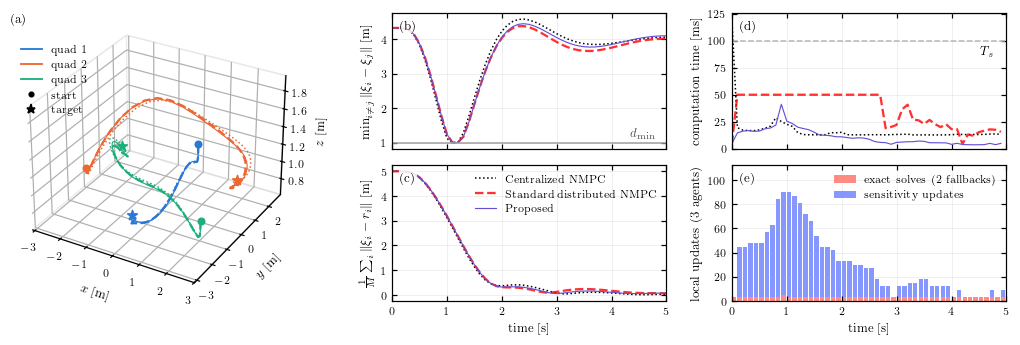

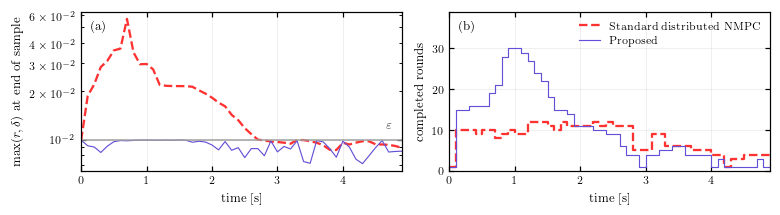

controller                | mean track. err. [m] | min dist [m] | mean t [ms] | max t [ms] | samples > Ts | converged | avg rounds | #exact | #sens | #fallback
--------------------------+----------------------+--------------+-------------+------------+--------------+-----------+------------+--------+-------+----------
Centralized NMPC          | 1.278                | 1.000        | 17.0        | 119.9      | 2%           | -         | -          | 50     | -     | -        
Standard distributed NMPC | 1.312                | 0.999        | 36.2        | 50.0       | 0%           | 46%       | 7.9        | 1179   | 0     | 0        
Proposed                  | 1.295                | 0.999        | 10.8        | 41.1       | 0%           | 100%      | 10.4       | 152    | 1405  | 2        

max closed-loop position deviation, proposed vs. standard: 8.66e-02 m


In [21]:
ref_P = np.broadcast_to(targets, (N_STEPS + 1, M, 3))
results_figure(logs, ref_P, 'fig_closedloop_rt.pdf', panel_a='3d')
admm_figure(logs, 'fig_closedloop_rt_admm.pdf')
summary(logs, ref_P)

## 8. Scenario 2: tracking three intersecting elliptical orbits

Each quadrotor follows a reference along its own ellipse in the plane $z_{\rm ref}=1$ m
(semi-axes $a=2.5$ m, $b=0.6$ m, major axes rotated by 90°, 150° and 30°), one lap in 8 s:

$$
r_i(t) = \begin{bmatrix} R(\varphi_i)\begin{bmatrix} a\cos(\omega t+\psi_i)\\ b\sin(\omega t+\psi_i)\end{bmatrix}\\ z_{\rm ref}\end{bmatrix},
\qquad \omega = 2\pi/T_{\rm lap}.
$$

The references pass close to the centre at nearly the same time, twice per lap, where they come
closer than $d_{\min}$ to each other. The reference over the horizon (position and velocity)
replaces the target in the local parameter.

Stage cost: $\ell_i = 10\|\xi_{i,k}-r_{i,k}\|^2 + \|v_{i,k}-\dot r_{i,k}\|^2 + \|(\theta,\phi,\psi)\|^2
+ \|(\dot\theta,\dot\phi,\dot\psi)\|^2 + (u-u_{\rm hover})^\top R\,(u-u_{\rm hover})$.

In [25]:
R_SWITCH_TR = 1.01e4     # switching threshold on max(primal, dual residual)

A_ELL, B_ELL, Z_REF = 2.5, 0.6, 1.0
PHI_ELL = np.deg2rad([90.0, 150.0, 30.0])     # orientation of the major axes
PSI_ELL = np.array([0.0, 0.15, -0.10])        # small phase offsets break the exact symmetry
T_LAP = 8.0
OMEGA = 2 * np.pi / T_LAP
N_TR = 3*int(round(T_LAP / Ts))                 # one lap


def ref_pos_vel(i, t):
    """Reference position (3,) and velocity (3,) of quadrotor i at time t."""
    th = OMEGA * t + PSI_ELL[i]
    c, s = np.cos(PHI_ELL[i]), np.sin(PHI_ELL[i])
    Rm = np.array([[c, -s], [s, c]])
    p = Rm @ np.array([A_ELL * np.cos(th), B_ELL * np.sin(th)])
    v = Rm @ np.array([-A_ELL * OMEGA * np.sin(th), B_ELL * OMEGA * np.cos(th)])
    return np.array([p[0], p[1], Z_REF]), np.array([v[0], v[1], 0.0])


def ref_horizon(i, t0):
    """6 x (N+1) reference over the horizon: position (rows 0-2) and velocity (rows 3-5)."""
    return np.stack([np.concatenate(ref_pos_vel(i, t0 + k * Ts)) for k in range(N + 1)], axis=1)


def track_stage(x, u, rk):
    return (10 * ca.sumsqr(x[3:6] - rk[0:3]) + ca.sumsqr(x[9:12] - rk[3:6])
            + ca.sumsqr(x[0:3]) + ca.sumsqr(x[6:9]) + ca.sumsqr(np.sqrt(Rw) * (u - u_hover)))


def track_terminal(x, rk):
    return (10 * ca.sumsqr(x[3:6] - rk[0:3]) + ca.sumsqr(x[9:12] - rk[3:6])
            + ca.sumsqr(x[0:3]) + ca.sumsqr(x[6:9]))


def track_cost(X, U, ref):
    Rf = ca.reshape(ref, 6, N + 1)
    return sum(track_stage(X[:, k], U[:, k], Rf[:, k]) for k in range(N)) + track_terminal(X[:, N], Rf[:, N])


tr_agents = [Agent(i, 6 * (N + 1), track_cost) for i in range(M)]
central_tr = Central(6 * (N + 1), track_cost)

x_start_tr = [x_init(ref_pos_vel(i, 0.0)[0]) for i in range(M)]
refs0 = [ref_horizon(i, 0.0) for i in range(M)]
X0_tr = []                                     # guess: positions and velocities on the references
for i in range(M):
    X = np.tile(x_start_tr[i][:, None], (1, N + 1)); X[3:6, :] = refs0[i][0:3]; X[9:12, :] = refs0[i][3:6]
    X[:, 0] = x_start_tr[i]; X0_tr.append(X)

logs_tr = run_all(tr_agents, central_tr, x_start_tr, X0_tr,
                  lambda k: [ref_horizon(i, k * Ts) for i in range(M)], N_TR, R_SWITCH_TR)
with open(RES_DIR / 'logs_tracking_rt.pkl', 'wb') as f:
    pickle.dump(logs_tr, f)

offline ADMM initialization: 78 rounds
Centralized NMPC             simulated in    5.2 s
Standard distributed NMPC    simulated in   42.4 s
Proposed                     simulated in   19.5 s


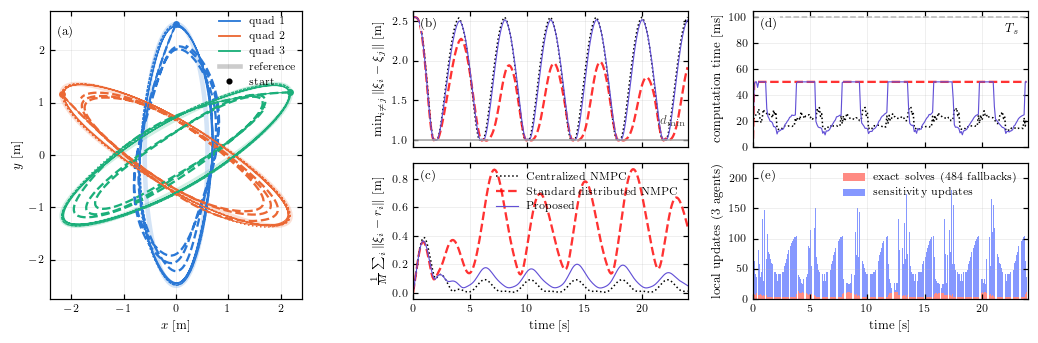

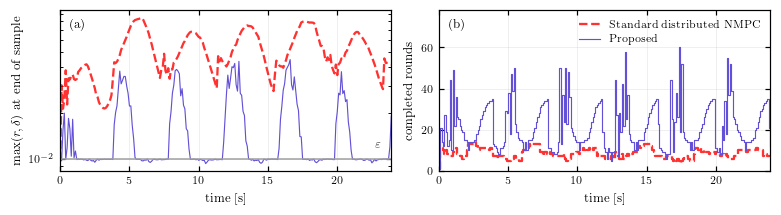

controller                | mean track. err. [m] | min dist [m] | mean t [ms] | max t [ms] | samples > Ts | converged | avg rounds | #exact | #sens | #fallback
--------------------------+----------------------+--------------+-------------+------------+--------------+-----------+------------+--------+-------+----------
Centralized NMPC          | 0.056                | 1.000        | 20.0        | 30.8       | 0%           | -         | -          | 240    | -     | -        
Standard distributed NMPC | 0.434                | 0.995        | 49.8        | 50.0       | 0%           | 0%        | 8.4        | 6078   | 0     | 0        
Proposed                  | 0.106                | 0.999        | 30.4        | 50.0       | 0%           | 63%       | 21.6       | 1204   | 14357 | 484      

max closed-loop position deviation, proposed vs. standard: 8.65e-01 m


In [26]:
ref_P_tr = np.array([[ref_pos_vel(i, k * Ts)[0] for i in range(M)] for k in range(N_TR + 1)])
ref_orbit = np.array([[ref_pos_vel(i, t)[0] for i in range(M)] for t in np.linspace(0, T_LAP, 400)])
results_figure(logs_tr, ref_P_tr, 'fig_tracking_rt.pdf', panel_a='xy', ref_orbit=ref_orbit)
admm_figure(logs_tr, 'fig_tracking_rt_admm.pdf')
summary(logs_tr, ref_P_tr)

## 9. Animations (optional)

Animated 3D closed-loop trajectories of the proposed method, saved as GIFs in `figures/`.

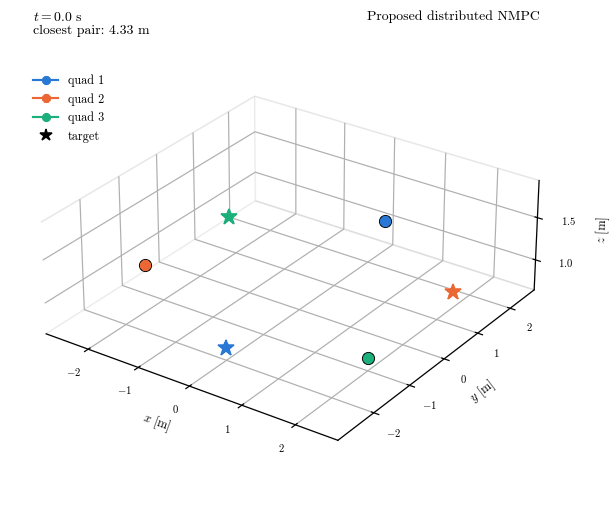

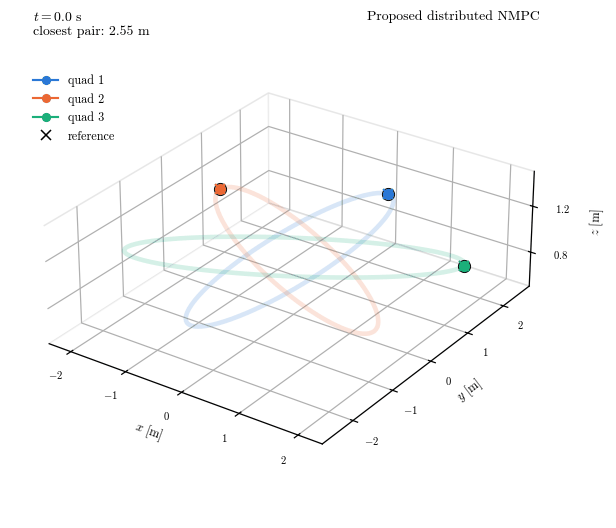

In [24]:
from matplotlib import animation
from IPython.display import Image, display


def make_gif_3d(log, fname, targets=None, ref_fun=None, trail=None, view=(28, -55), dpi=110,
                label='Proposed distributed NMPC'):
    """Animate the closed-loop positions in log['x'] and save a GIF (one frame per sample).

    targets : (M, 3) fixed targets, drawn as stars
    ref_fun : ref_fun(i, t) -> (3,) moving reference, drawn as orbit and moving cross
    trail   : number of past samples shown as trail (None = full path)
    """
    P = np.asarray(log['x'])[:, :, 3:6]
    T = P.shape[0]
    tt = np.arange(T) * Ts
    R = None if ref_fun is None else np.array([[ref_fun(i, t) for i in range(M)] for t in tt])
    pts = np.vstack([P.reshape(-1, 3)] + ([np.asarray(targets)] if targets is not None else [])
                    + ([R.reshape(-1, 3)] if R is not None else []))
    c, half = (pts.min(0) + pts.max(0)) / 2, np.maximum((pts.max(0) - pts.min(0)) / 2 * 1.1, 0.5)
    lo, hi = c - half, c + half

    rc = {'text.usetex': False, 'font.family': 'serif', 'font.serif': ['cmr10'],
          'mathtext.fontset': 'cm', 'axes.formatter.use_mathtext': True, 'font.size': 9}
    with plt.rc_context(rc):
        fig = plt.figure(figsize=(5.6, 4.8))
        ax = fig.add_subplot(111, projection='3d')
        ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
        span = hi - lo
        ax.set_box_aspect((span[0], span[1], max(span[2], 0.35 * max(span[0], span[1]))), zoom=0.95)
        ax.zaxis.set_major_locator(plt.MaxNLocator(3))
        fig.subplots_adjust(left=0.0, right=0.93, bottom=0.0, top=1.0)
        ax.set_xlabel('$x$ [m]'); ax.set_ylabel('$y$ [m]'); ax.set_zlabel('$z$ [m]')
        for a in (ax.xaxis, ax.yaxis, ax.zaxis):
            a.pane.set_facecolor('white'); a.pane.set_edgecolor('#d0d0d0')
        ax.view_init(*view)

        if R is not None:
            for i in range(M):
                ax.plot(*R[:, i].T, color=AGENT_COLORS[i], lw=3.0, alpha=0.18)
        if targets is not None:
            for i in range(M):
                ax.plot(*np.asarray(targets)[i], marker='*', ms=11, color=AGENT_COLORS[i], ls='')
        for i in range(M):
            ax.plot(*P[0, i], marker='o', ms=4, color=AGENT_COLORS[i], ls='', alpha=0.6)

        trails, shadows, heads, refm = [], [], [], []
        for i in range(M):
            trails.append(ax.plot([], [], [], color=AGENT_COLORS[i], lw=1.6)[0])
            shadows.append(ax.plot([], [], [], color='0.55', lw=0.8, alpha=0.5)[0])
            heads.append(ax.plot([], [], [], marker='o', ms=8, color=AGENT_COLORS[i], mec='k', mew=0.6, ls='')[0])
            if R is not None:
                refm.append(ax.plot([], [], [], marker='x', ms=7, mew=1.5, color=AGENT_COLORS[i], ls='')[0])
        txt = ax.text2D(0.02, 0.98, '', transform=ax.transAxes, va='top')
        ax.text2D(0.98, 0.98, label, transform=ax.transAxes, va='top', ha='right')
        h = [Line2D([], [], color=AGENT_COLORS[i], marker='o', ms=5, lw=1.4, label=f'quad {i + 1}')
             for i in range(M)]
        if targets is not None:
            h.append(Line2D([], [], color='k', marker='*', ms=8, ls='', label='target'))
        if R is not None:
            h.append(Line2D([], [], color='k', marker='x', ms=6, ls='', label='reference'))
        ax.legend(handles=h, loc='upper left', bbox_to_anchor=(0.0, 0.88), frameon=False, fontsize=8)

        def update(k):
            k0 = 0 if trail is None else max(0, k - trail)
            for i in range(M):
                seg = P[k0:k + 1, i]
                trails[i].set_data_3d(seg[:, 0], seg[:, 1], seg[:, 2])
                shadows[i].set_data_3d(seg[:, 0], seg[:, 1], np.full(len(seg), lo[2]))
                heads[i].set_data_3d([P[k, i, 0]], [P[k, i, 1]], [P[k, i, 2]])
                if R is not None:
                    refm[i].set_data_3d([R[k, i, 0]], [R[k, i, 1]], [R[k, i, 2]])
            txt.set_text(rf'$t = {tt[k]:.1f}$ s' + '\n' + f'closest pair: {min_pair_distance(P[k:k + 1])[0]:.2f} m')
            return trails + shadows + heads + refm + [txt]

        anim = animation.FuncAnimation(fig, update, frames=T, interval=1000 * Ts)
        anim.save(FIG_DIR / fname, writer=animation.PillowWriter(fps=round(1 / Ts)), dpi=dpi)
        plt.close(fig)
    display(Image(filename=FIG_DIR / fname))


make_gif_3d(logs['sens'], 'closedloop_point_to_point_rt.gif', targets=targets)
make_gif_3d(logs_tr['sens'], 'closedloop_tracking_rt.gif', ref_fun=lambda i, t: ref_pos_vel(i, t)[0],
            trail=int(2.0 / Ts))